# NUMPY

#1. Linear Thend

In [43]:
import pandas as pd
import numpy as np

# Generate linear data
x = np.linspace(0, 10, 50)
y = 2 * x + 1 + np.random.normal(0, 1, 50)

df = pd.DataFrame({
    'Input': x,
    'Output': y,
    'Category': np.random.choice(['Group A', 'Group B'], 50)
})
df

,Input,Output,Category
0,0.000000,0.338001,Group A
1,0.204082,2.914348,Group A
2,0.408163,2.259886,Group B
3,0.612245,1.958882,Group B
4,0.816327,3.814758,Group B
5,1.020408,3.648111,Group A
6,1.224490,3.741411,Group A
7,1.428571,5.306967,Group A
8,1.632653,4.389739,Group A
9,1.836735,5.114356,Group A


In [44]:
df[['Input', 'Output']].corr()

,Input,Output
Input,1.000000,0.989608
Output,0.989608,1.000000


In [45]:
m, b = np.polyfit(df['Input'], df['Output'], 1)
print("Slope:", m)
print("Intercept:", b)

Slope: 1.9981754348964316
Intercept: 1.1541040304027421


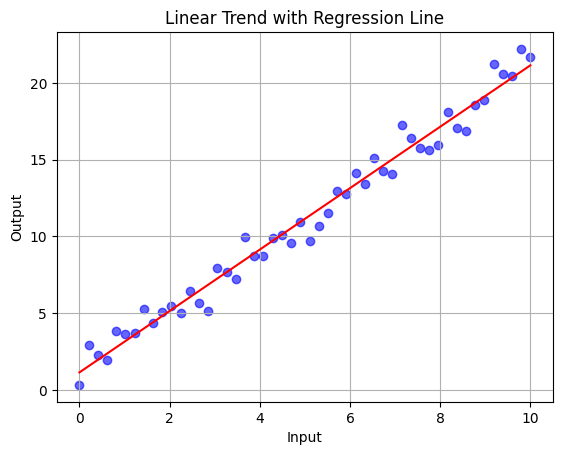

In [46]:
import matplotlib.pyplot as plt
import numpy as np

plt.scatter(df['Input'], df['Output'], color='blue', alpha=0.6)

# Regression line
m, b = np.polyfit(df['Input'], df['Output'], 1)
plt.plot(df['Input'], m * df['Input'] + b, color='red')

plt.title('Linear Trend with Regression Line')
plt.xlabel('Input')
plt.ylabel('Output')
plt.grid(True)
plt.show()

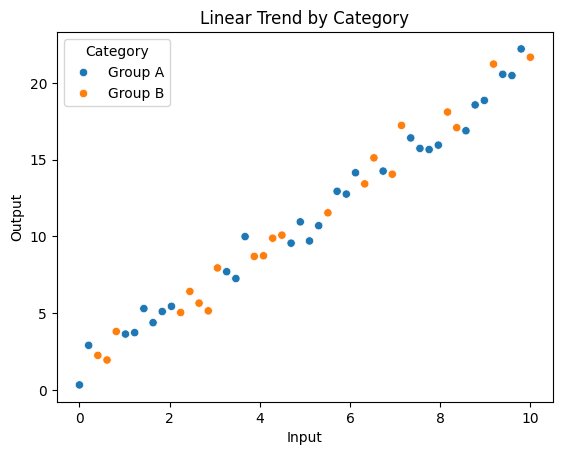

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=df, x='Input', y='Output', hue='Category')
plt.title('Linear Trend by Category')
plt.show()

In [48]:
new_x = 7.5
predicted_y = m * new_x + b
predicted_y

np.float64(16.14041979212598)

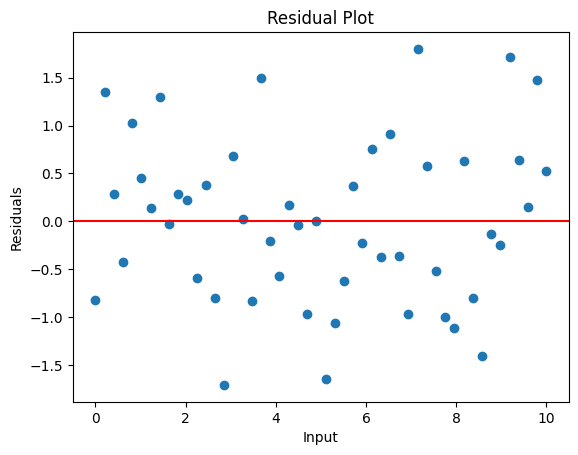

In [49]:
residuals = df['Output'] - (m * df['Input'] + b)

plt.scatter(df['Input'], residuals)
plt.axhline(0, color='red')
plt.title('Residual Plot')
plt.xlabel('Input')
plt.ylabel('Residuals')
plt.show()

#2. Time Series Volatility

In [50]:
import pandas as pd
import numpy as np

# Generate random walk data
dates = pd.date_range('2026-01-01', periods=100)
values = np.cumsum(np.random.randn(100))
status = np.where(values > 0, 'Positive', 'Negative')

df = pd.DataFrame({
    'Date': dates,
    'Value': values,
    'Status': status
})
df

,Date,Value,Status
0,2026-01-01,-0.330760,Negative
1,2026-01-02,-0.403990,Negative
2,2026-01-03,-0.767687,Negative
3,2026-01-04,-0.324707,Negative
4,2026-01-05,-0.257948,Negative
...,...,...,...
95,2026-04-06,22.755035,Positive
96,2026-04-07,22.509909,Positive
97,2026-04-08,23.052592,Positive
98,2026-04-09,24.564927,Positive


In [51]:
df['Change'] = df['Value'].diff()
df

,Date,Value,Status,Change
0,2026-01-01,-0.330760,Negative,NaN
1,2026-01-02,-0.403990,Negative,-0.073230
2,2026-01-03,-0.767687,Negative,-0.363697
3,2026-01-04,-0.324707,Negative,0.442980
4,2026-01-05,-0.257948,Negative,0.066759
...,...,...,...,...
95,2026-04-06,22.755035,Positive,0.256862
96,2026-04-07,22.509909,Positive,-0.245126
97,2026-04-08,23.052592,Positive,0.542683
98,2026-04-09,24.564927,Positive,1.512335


In [52]:
df['MA_10'] = df['Value'].rolling(window=10).mean()

In [53]:
df['Volatility_10'] = df['Value'].rolling(window=10).std()

In [54]:
df['High_Volatility'] = df['Volatility_10'] > df['Volatility_10'].mean()

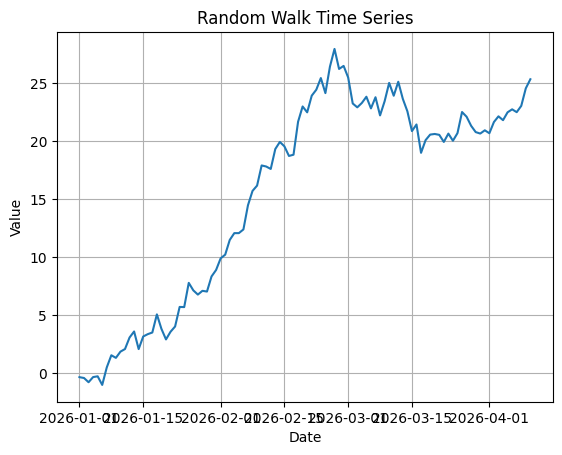

In [55]:
import matplotlib.pyplot as plt

plt.plot(df['Date'], df['Value'], label='Value')
plt.title('Random Walk Time Series')
plt.xlabel('Date')
plt.ylabel('Value')
plt.grid(True)
plt.show()

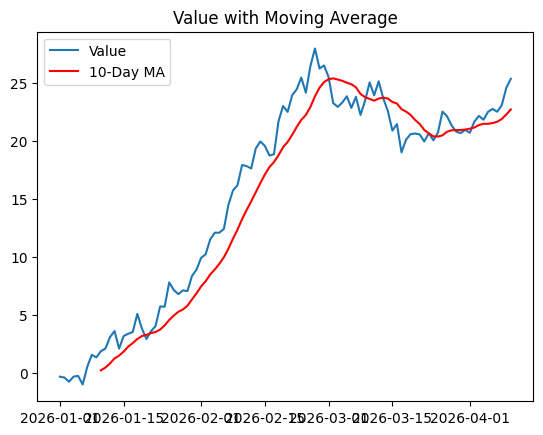

In [56]:
plt.plot(df['Date'], df['Value'], label='Value')
plt.plot(df['Date'], df['MA_10'], label='10-Day MA', color='red')
plt.title('Value with Moving Average')
plt.legend()
plt.show()

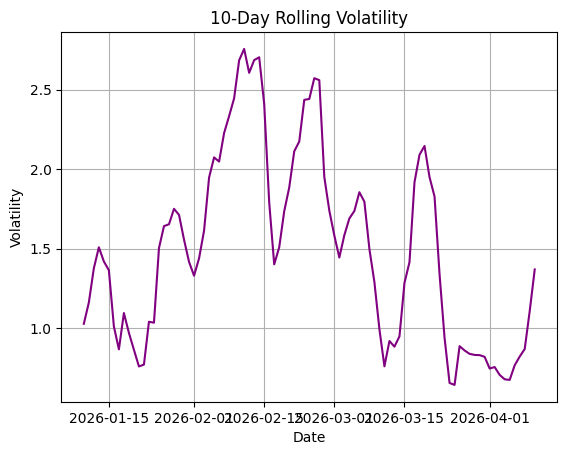

In [57]:
plt.plot(df['Date'], df['Volatility_10'], color='purple')
plt.title('10-Day Rolling Volatility')
plt.xlabel('Date')
plt.ylabel('Volatility')
plt.grid(True)
plt.show()

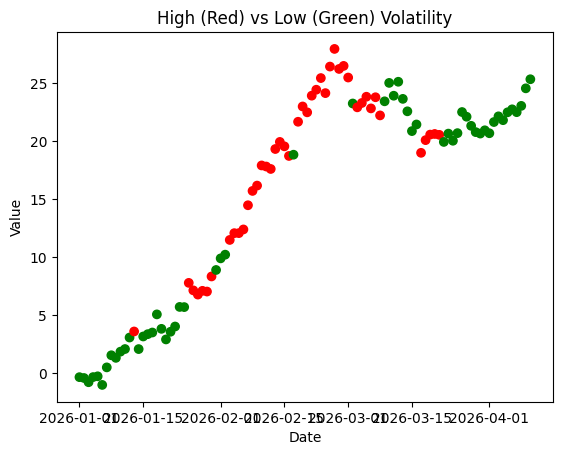

In [58]:
colors = ['red' if hv else 'green' for hv in df['High_Volatility']]

plt.scatter(df['Date'], df['Value'], c=colors)
plt.title('High (Red) vs Low (Green) Volatility')
plt.xlabel('Date')
plt.ylabel('Value')
plt.show()

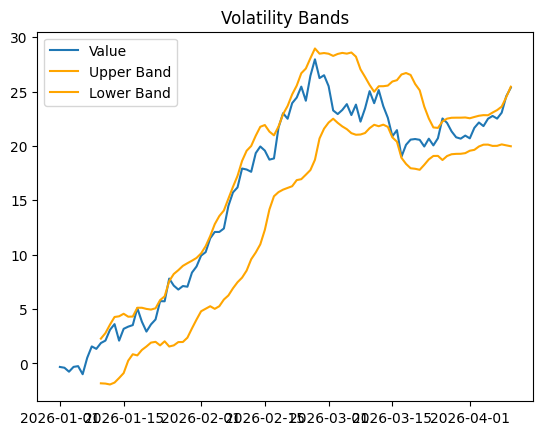

In [59]:
df['Upper_Band'] = df['MA_10'] + 2 * df['Volatility_10']
df['Lower_Band'] = df['MA_10'] - 2 * df['Volatility_10']

plt.plot(df['Date'], df['Value'], label='Value')
plt.plot(df['Date'], df['Upper_Band'], label='Upper Band', color='orange')
plt.plot(df['Date'], df['Lower_Band'], label='Lower Band', color='orange')
plt.legend()
plt.title('Volatility Bands')
plt.show()

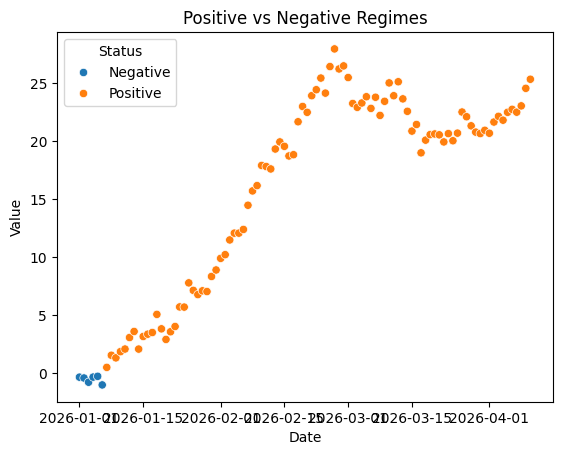

In [60]:
import seaborn as sns

sns.scatterplot(data=df, x='Date', y='Value', hue='Status')
plt.title('Positive vs Negative Regimes')
plt.show()

#3. Categorical Distribution

In [61]:
import pandas as pd
import numpy as np
import seaborn as sns

# Simulate normal distributions for three groups
data = {
    'Department': ['Sales'] * 50 + ['IT'] * 50 + ['HR'] * 50,
    'Salary_K': np.concatenate([
        np.random.normal(50, 5, 50),
        np.random.normal(70, 10, 50),
        np.random.normal(45, 3, 50)
    ]),
    'Satisfaction': np.random.randint(1, 10, 150)
}

df = pd.DataFrame(data)
df

,Department,Salary_K,Satisfaction
0,Sales,43.012416,4
1,Sales,47.183006,8
2,Sales,49.440813,1
3,Sales,58.029265,3
4,Sales,51.385661,4
...,...,...,...
145,HR,43.610032,1
146,HR,44.456321,6
147,HR,44.242023,3
148,HR,44.064616,8


In [62]:
df.groupby('Department')['Salary_K'].mean()

,Salary_K
Department,
HR,44.166224
IT,71.200641
Sales,50.277870


In [63]:
df.groupby('Department')['Salary_K'].agg(['min', 'max'])

,min,max
Department,,
HR,38.439990,54.276833
IT,45.094570,95.010448
Sales,39.557149,68.041919


In [64]:
df.groupby('Department')['Satisfaction'].describe()

,count,mean,std,min,25%,50%,75%,max
Department,,,,,,,,
HR,50.0,5.14,2.618693,1.0,3.00,5.0,8.00,9.0
IT,50.0,5.56,2.872530,1.0,2.25,6.0,8.00,9.0
Sales,50.0,5.06,2.683358,1.0,3.00,5.0,7.75,9.0


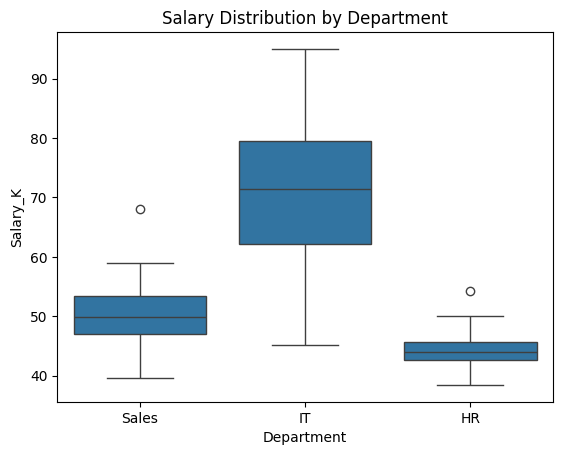

In [65]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=df, x='Department', y='Salary_K')
plt.title('Salary Distribution by Department')
plt.show()

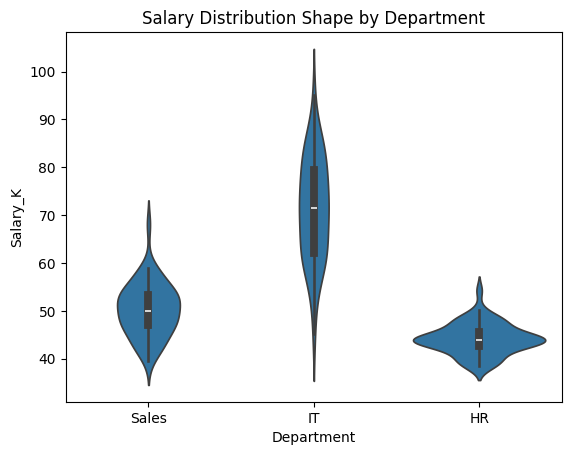

In [66]:
sns.violinplot(data=df, x='Department', y='Salary_K')
plt.title('Salary Distribution Shape by Department')
plt.show()

/tmp/ipykernel_1284/3524620158.py:1: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




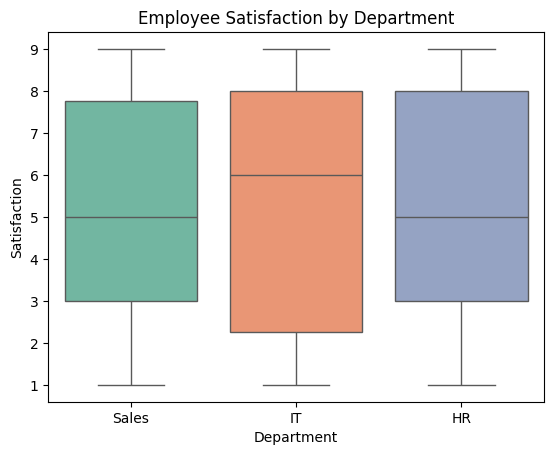

In [67]:
sns.boxplot(data=df, x='Department', y='Satisfaction', palette='Set2')
plt.title('Employee Satisfaction by Department')
plt.show()

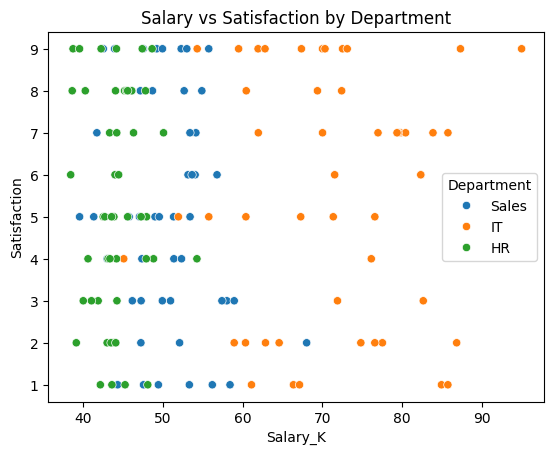

In [68]:
sns.scatterplot(data=df, x='Salary_K', y='Satisfaction', hue='Department')
plt.title('Salary vs Satisfaction by Department')
plt.show()

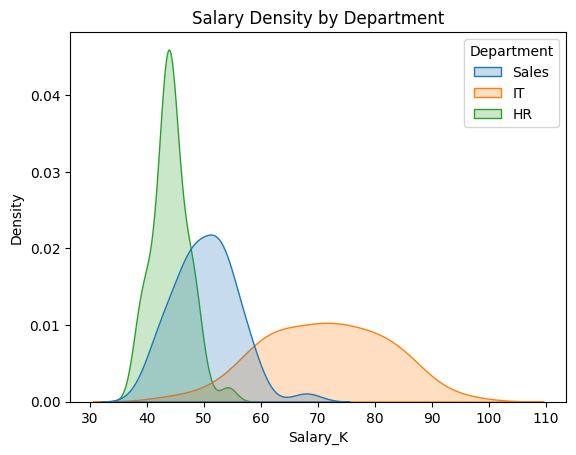

In [69]:
sns.kdeplot(data=df, x='Salary_K', hue='Department', fill=True)
plt.title('Salary Density by Department')
plt.show()

#4. Correlation Heatmap Data

In [70]:
import pandas as pd
import numpy as np

# Generate 3-column matrix relationship
matrix = np.random.rand(20, 3)

df = pd.DataFrame(matrix, columns=['Metric_A', 'Metric_B', 'Metric_C'])

# Adding an ID column for index plotting
df['ID'] = range(1, 21)
df

,Metric_A,Metric_B,Metric_C,ID
0,0.476405,0.295629,0.131026,1
1,0.897112,0.484404,0.739210,2
2,0.515642,0.137427,0.393571,3
3,0.182794,0.720549,0.296095,4
4,0.163026,0.960848,0.869433,5
5,0.233388,0.543985,0.127249,6
6,0.305488,0.146628,0.754826,7
7,0.015838,0.080720,0.957231,8
8,0.338151,0.405379,0.690859,9
9,0.673403,0.593021,0.237762,10


In [71]:
corr = df[['Metric_A', 'Metric_B', 'Metric_C']].corr()
corr

,Metric_A,Metric_B,Metric_C
Metric_A,1.000000,0.111483,-0.231131
Metric_B,0.111483,1.000000,-0.133863
Metric_C,-0.231131,-0.133863,1.000000


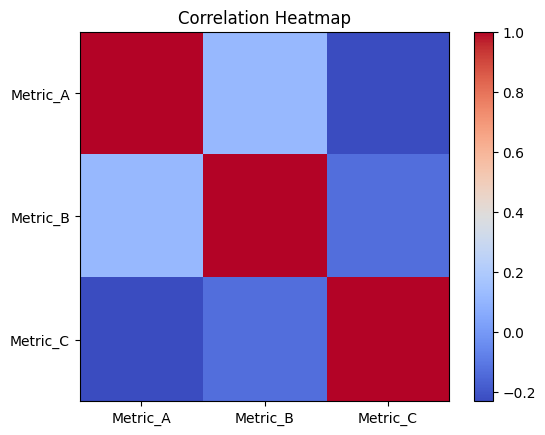

In [72]:
import matplotlib.pyplot as plt

plt.imshow(corr, cmap='coolwarm', interpolation='nearest')
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title('Correlation Heatmap')
plt.show()

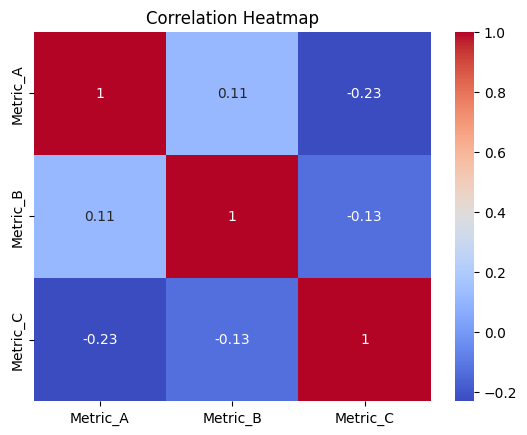

In [73]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

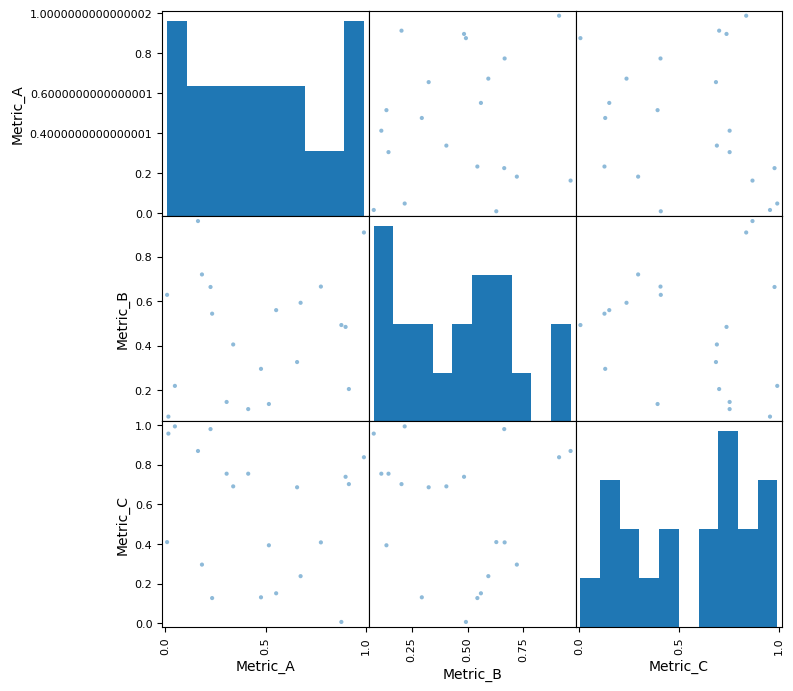

In [74]:
pd.plotting.scatter_matrix(df[['Metric_A', 'Metric_B', 'Metric_C']], figsize=(8, 8))
plt.show()

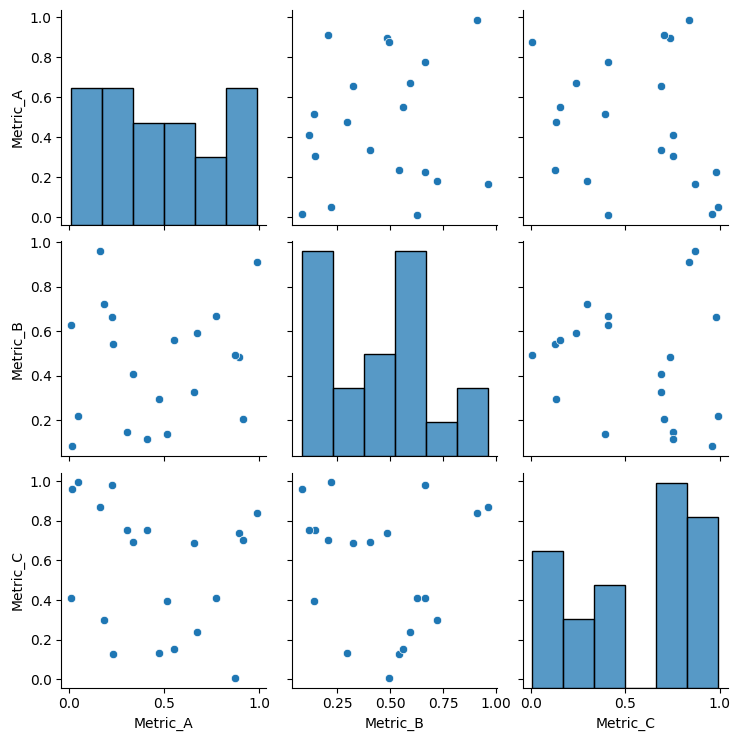

In [75]:
sns.pairplot(df[['Metric_A', 'Metric_B', 'Metric_C']])
plt.show()

#5. Multi-Variate Scatter

In [76]:
import pandas as pd
import numpy as np

# Generate 3 columns for X, Y, and Bubble Size
n = 30
df = pd.DataFrame({
    'Position_X': np.random.rand(n) * 100,
    'Position_Y': np.random.rand(n) * 100,
    'Impact_Size': np.random.rand(n) * 500
})
df

,Position_X,Position_Y,Impact_Size
0,52.076837,95.234315,53.715729
1,23.590248,29.491083,151.501329
2,81.284076,8.904468,315.875708
3,72.056407,96.825372,12.816294
4,5.726717,51.907084,8.683915
5,67.939219,46.935132,432.521535
6,92.346007,16.291821,355.178745
7,25.900107,69.970407,182.009163
8,15.217535,24.843486,344.339229
9,50.830435,57.171540,418.143663


In [77]:
df.loc[df['Impact_Size'].idxmax()]

,12
Position_X,4.484388
Position_Y,19.440870
Impact_Size,435.104197


In [78]:
df['Size_Normalized'] = df['Impact_Size'] / df['Impact_Size'].max() * 300

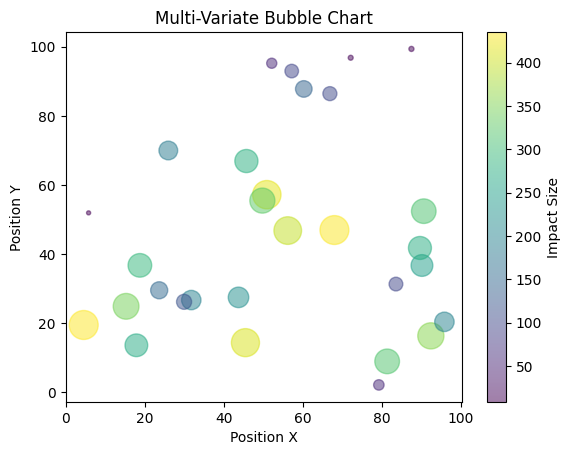

In [79]:
import matplotlib.pyplot as plt

plt.scatter(
    df['Position_X'],
    df['Position_Y'],
    s=df['Impact_Size'],   # bubble size
    alpha=0.5,
    c=df['Impact_Size'],   # color by impact
    cmap='viridis'
)

plt.title('Multi-Variate Bubble Chart')
plt.xlabel('Position X')
plt.ylabel('Position Y')
plt.colorbar(label='Impact Size')
plt.show()

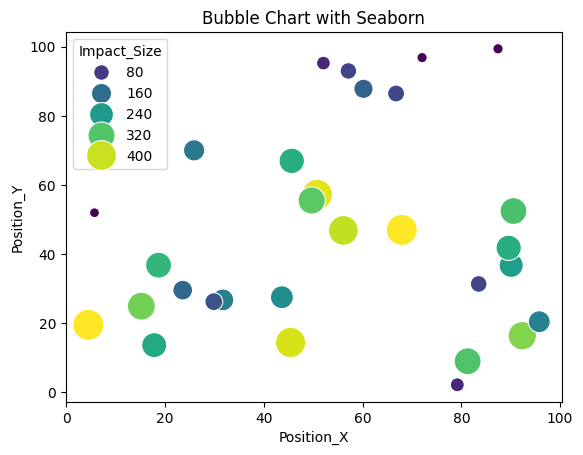

In [80]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=df,
    x='Position_X',
    y='Position_Y',
    size='Impact_Size',
    hue='Impact_Size',
    palette='viridis',
    sizes=(50, 500)
)

plt.title('Bubble Chart with Seaborn')
plt.show()

In [81]:
import plotly.express as px

fig = px.scatter(
    df,
    x='Position_X',
    y='Position_Y',
    size='Impact_Size',
    color='Impact_Size',
    title='Interactive Bubble Chart'
)

fig.show()

In [ ]:
for i in range(len(df)):
    plt.text(df['Position_X'][i], df['Position_Y'][i], str(i))